In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("Beans Multiclass Classification.csv")

In [5]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [7]:
df.shape

(13611, 17)

In [8]:
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='str')

In [9]:
print(df.columns.tolist())

['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


In [10]:
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [11]:
df.describe(include="object")

,Class
count,13611
unique,7
top,DERMASON
freq,3546


In [12]:
df.duplicated().sum()

np.int64(68)

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.shape

(13543, 17)

In [16]:
df["Class"].unique()

<ArrowStringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str

In [17]:
df["Class"].value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

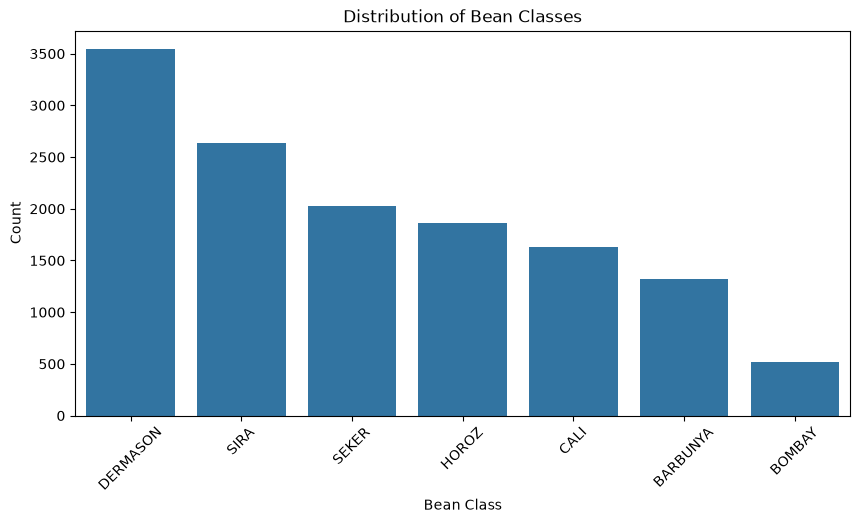

In [18]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="Class", order=df["Class"].value_counts().index)

plt.title("Distribution of Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Count")
plt.xticks(rotation=45)

plt.show()

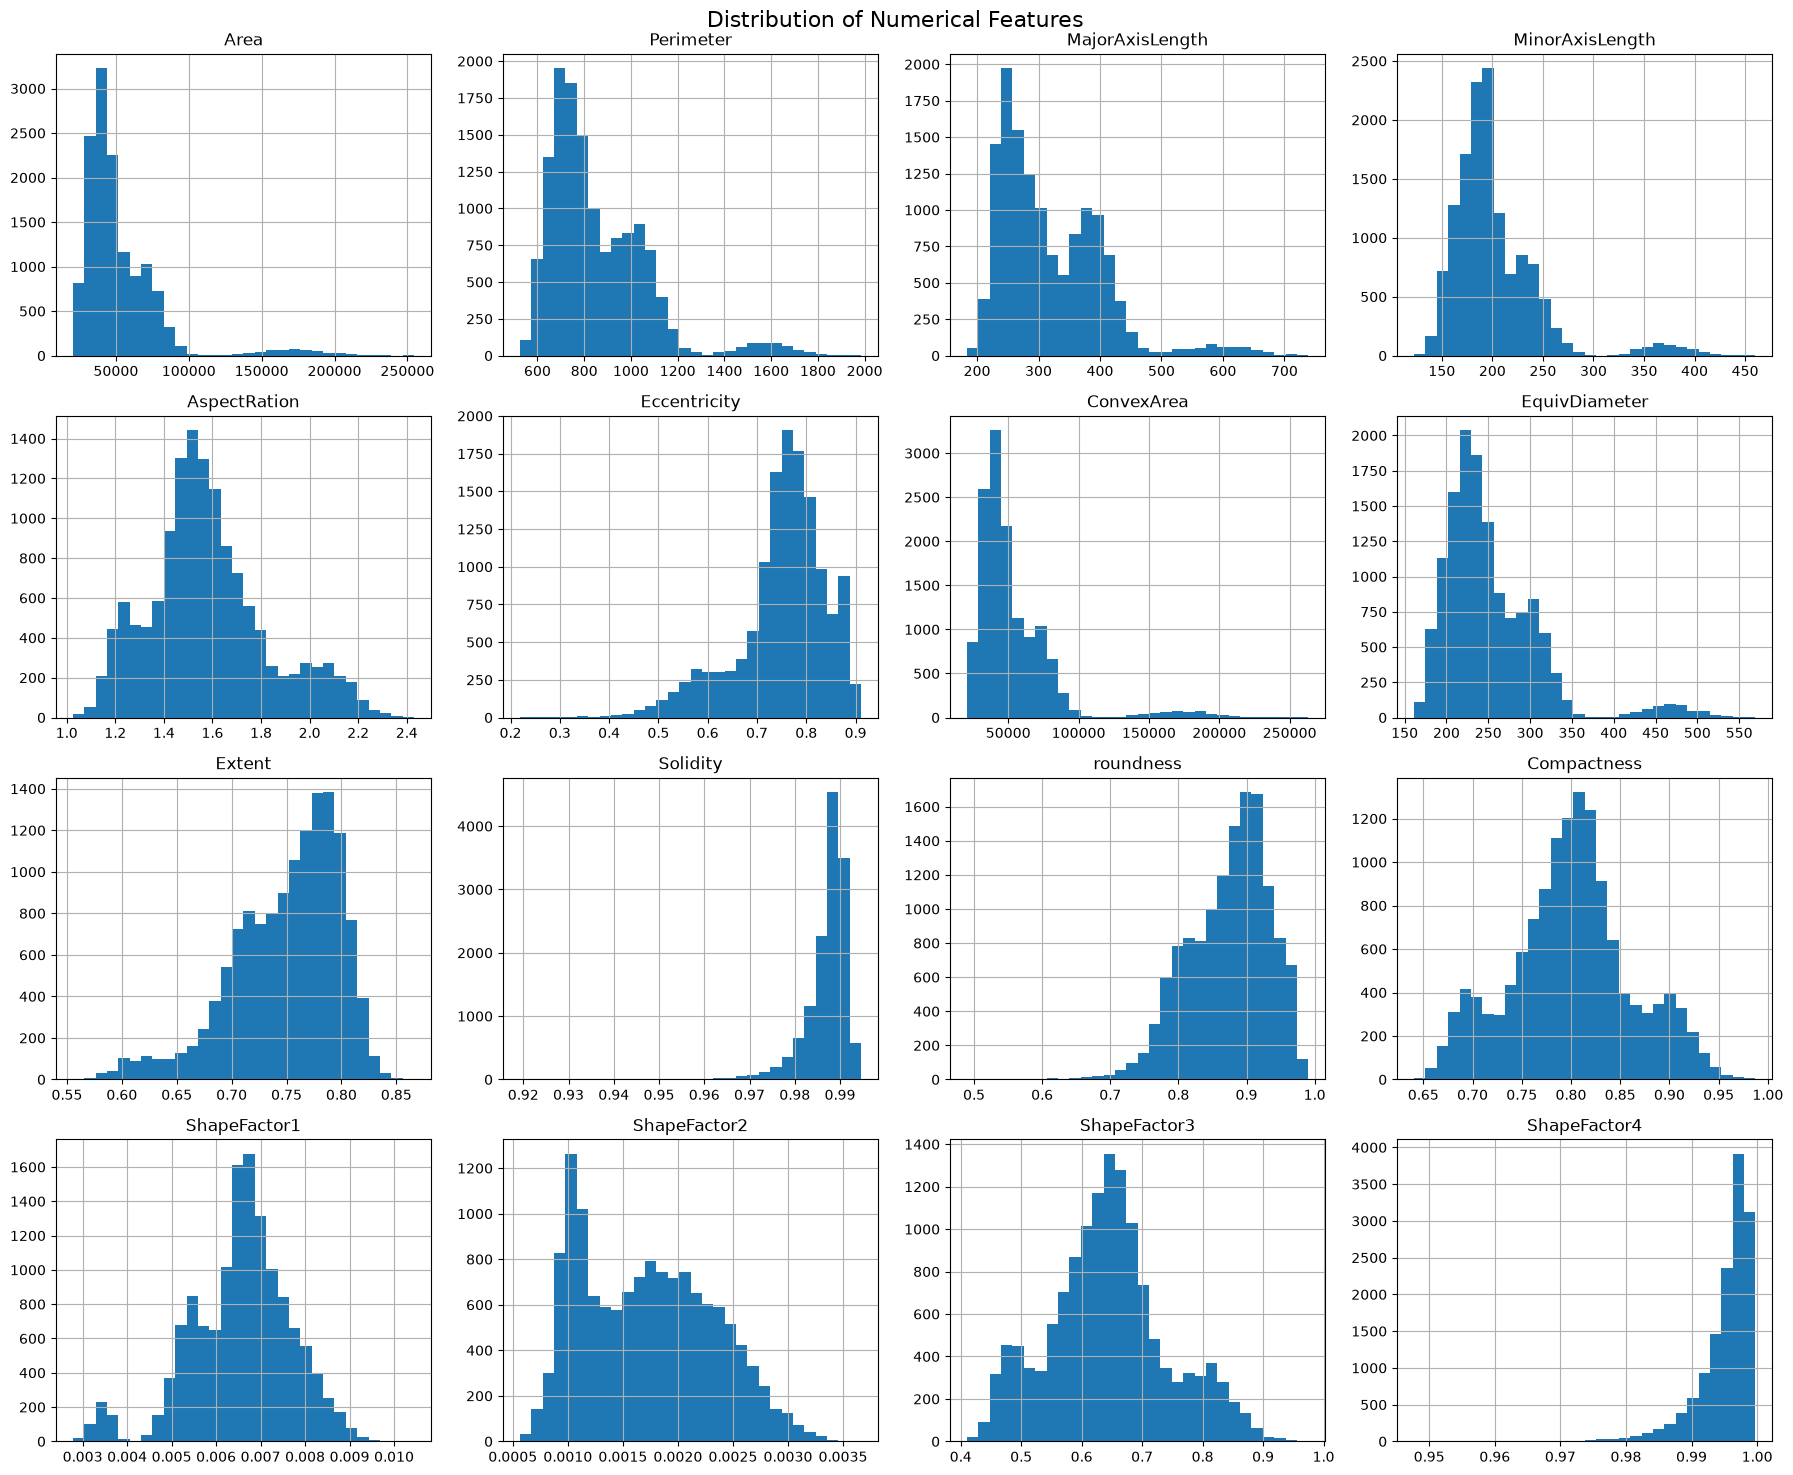

In [19]:
numerical_cols = df.drop("Class", axis=1).columns

df[numerical_cols].hist(figsize=(18, 15), bins=30)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [20]:
skewness = df[numerical_cols].skew().sort_values(ascending=False)
skewness

Area               2.947136
ConvexArea         2.936102
MinorAxisLength    2.232013
EquivDiameter      1.947303
Perimeter          1.628018
MajorAxisLength    1.365813
AspectRation       0.589045
ShapeFactor2       0.294332
ShapeFactor3       0.242767
Compactness        0.036309
ShapeFactor1      -0.530427
roundness         -0.648725
Extent            -0.895655
Eccentricity      -1.064932
Solidity          -2.546877
ShapeFactor4      -2.760125
dtype: float64

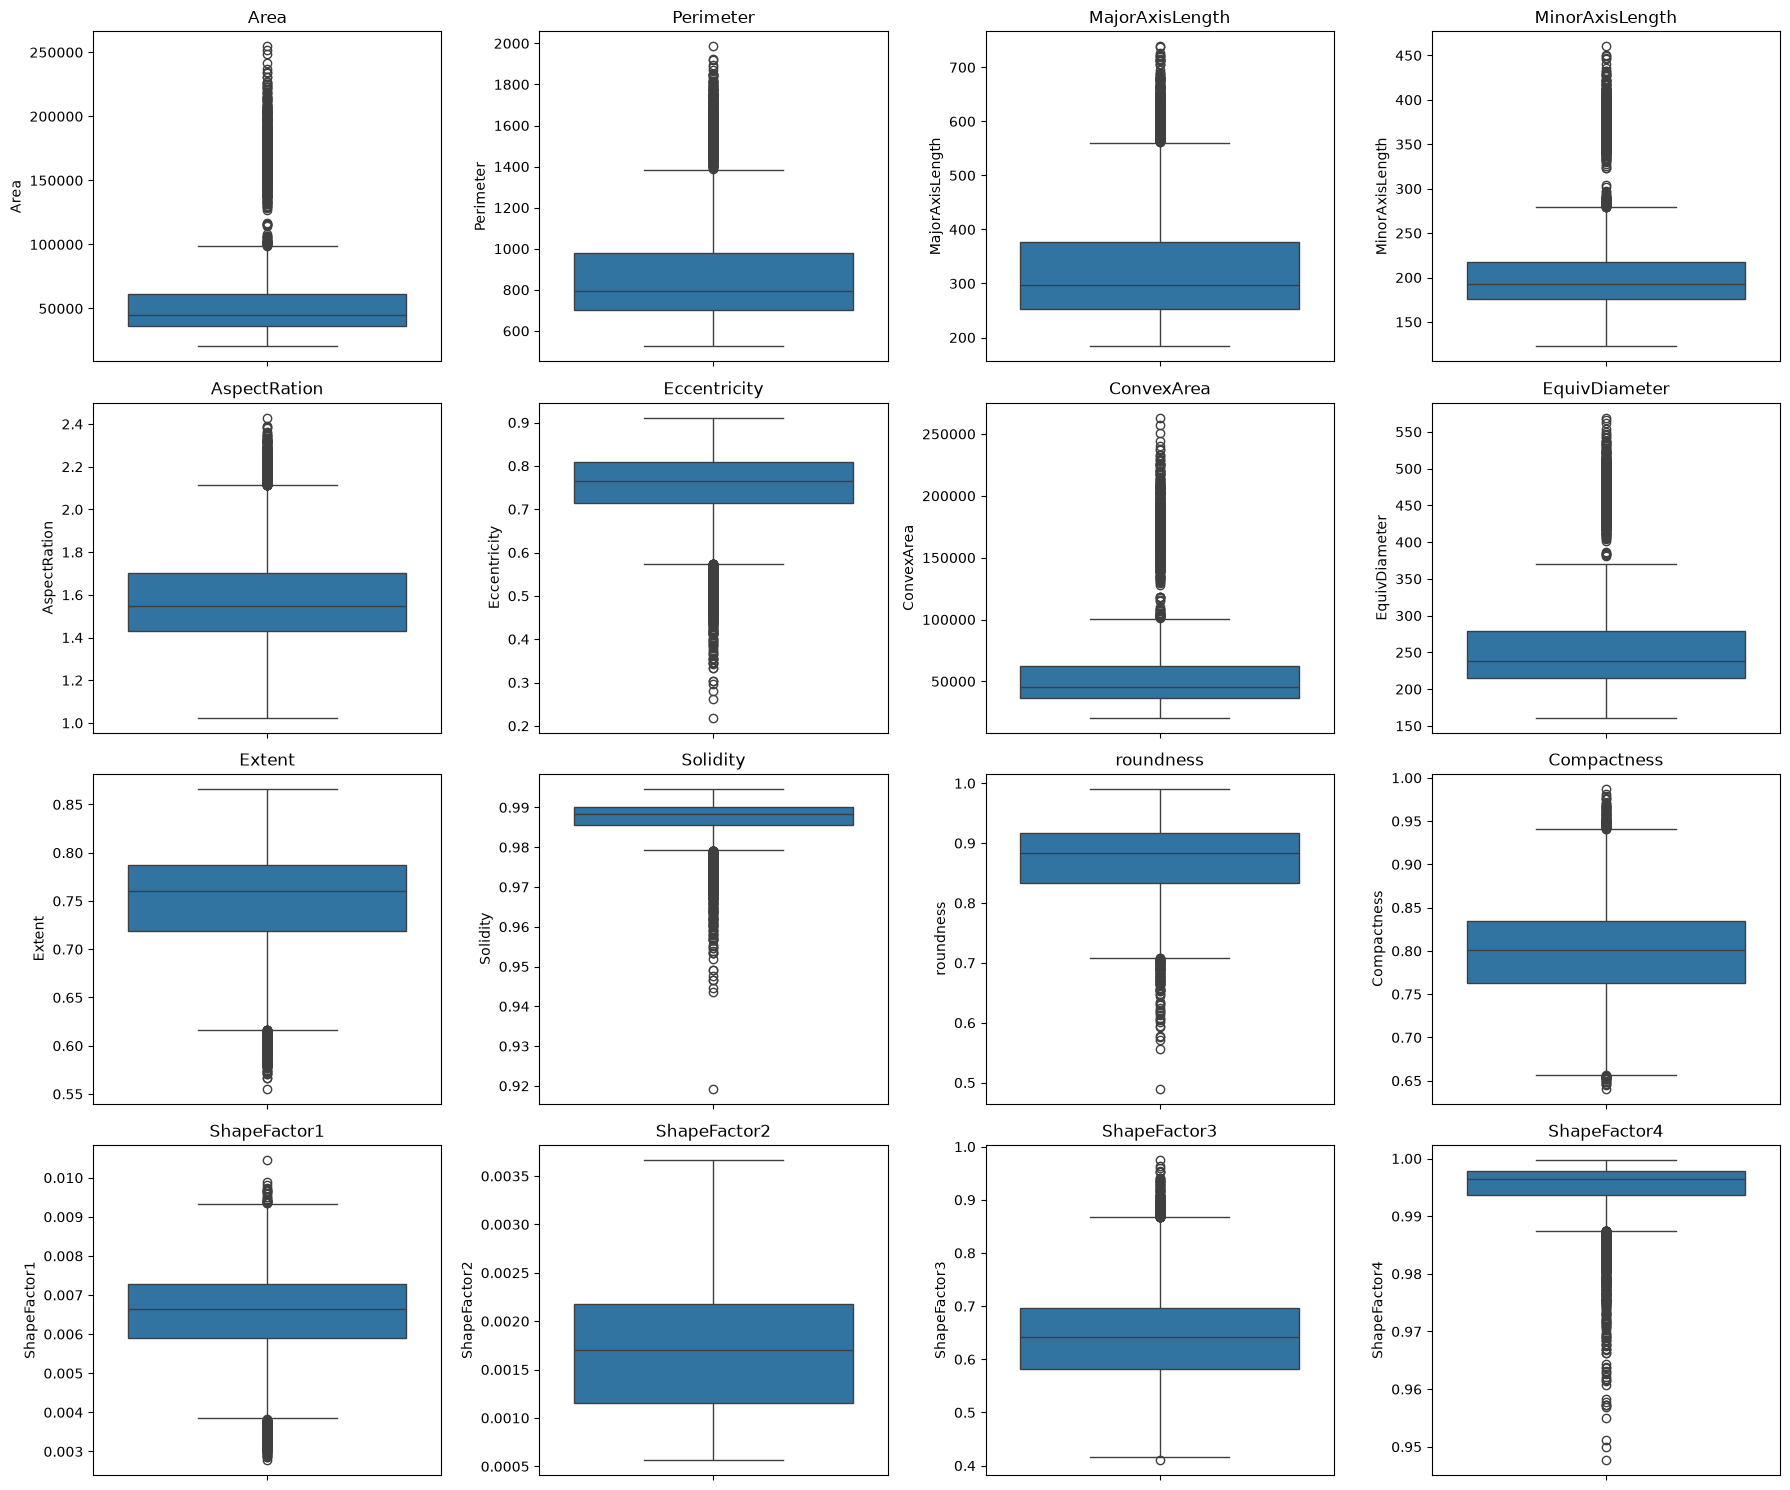

In [21]:
plt.figure(figsize=(18, 15))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

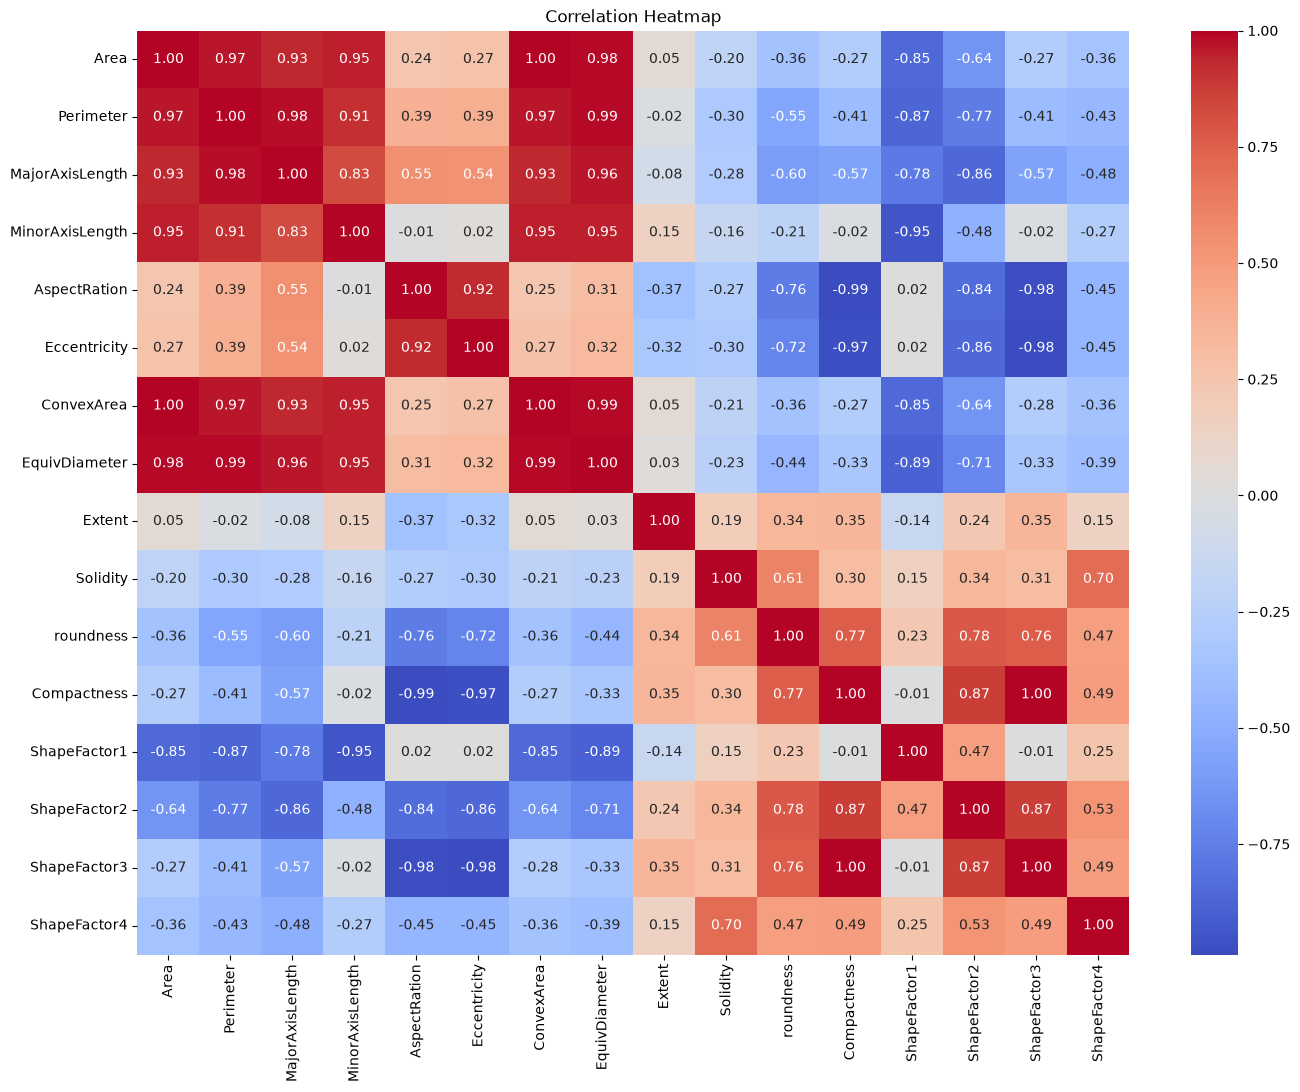

In [22]:
plt.figure(figsize=(16, 12))

corr = df[numerical_cols].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

Outlier Treatment: Boxplots indicated several potential outliers across the numerical features. Since the dataset represents different bean varieties with naturally varying physical characteristics, these observations may represent genuine variations rather than erroneous records. Therefore, outliers were retained to avoid unnecessary loss of information.

Correlation Analysis: Strong positive correlations are observed among size-related features such as Area, ConvexArea, Perimeter and EquivDiameter. Strong correlations are also observed among some shape-derived features. This indicates multicollinearity among several physical measurements.

In [23]:
skewed_features = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "MinorAxisLength",
    "ConvexArea",
    "EquivDiameter"
]

for col in skewed_features:
    df[col] = np.log1p(df[col])

In [24]:
df[skewed_features].skew()

Area               1.073117
Perimeter          0.848386
MajorAxisLength    0.640138
MinorAxisLength    1.307883
ConvexArea         1.067860
EquivDiameter      1.075826
dtype: float64

Skewness Treatment: Log transformation (np.log1p) was applied to highly positively skewed numerical features. The transformation reduced skewness considerably. The transformed features were retained for further model building.

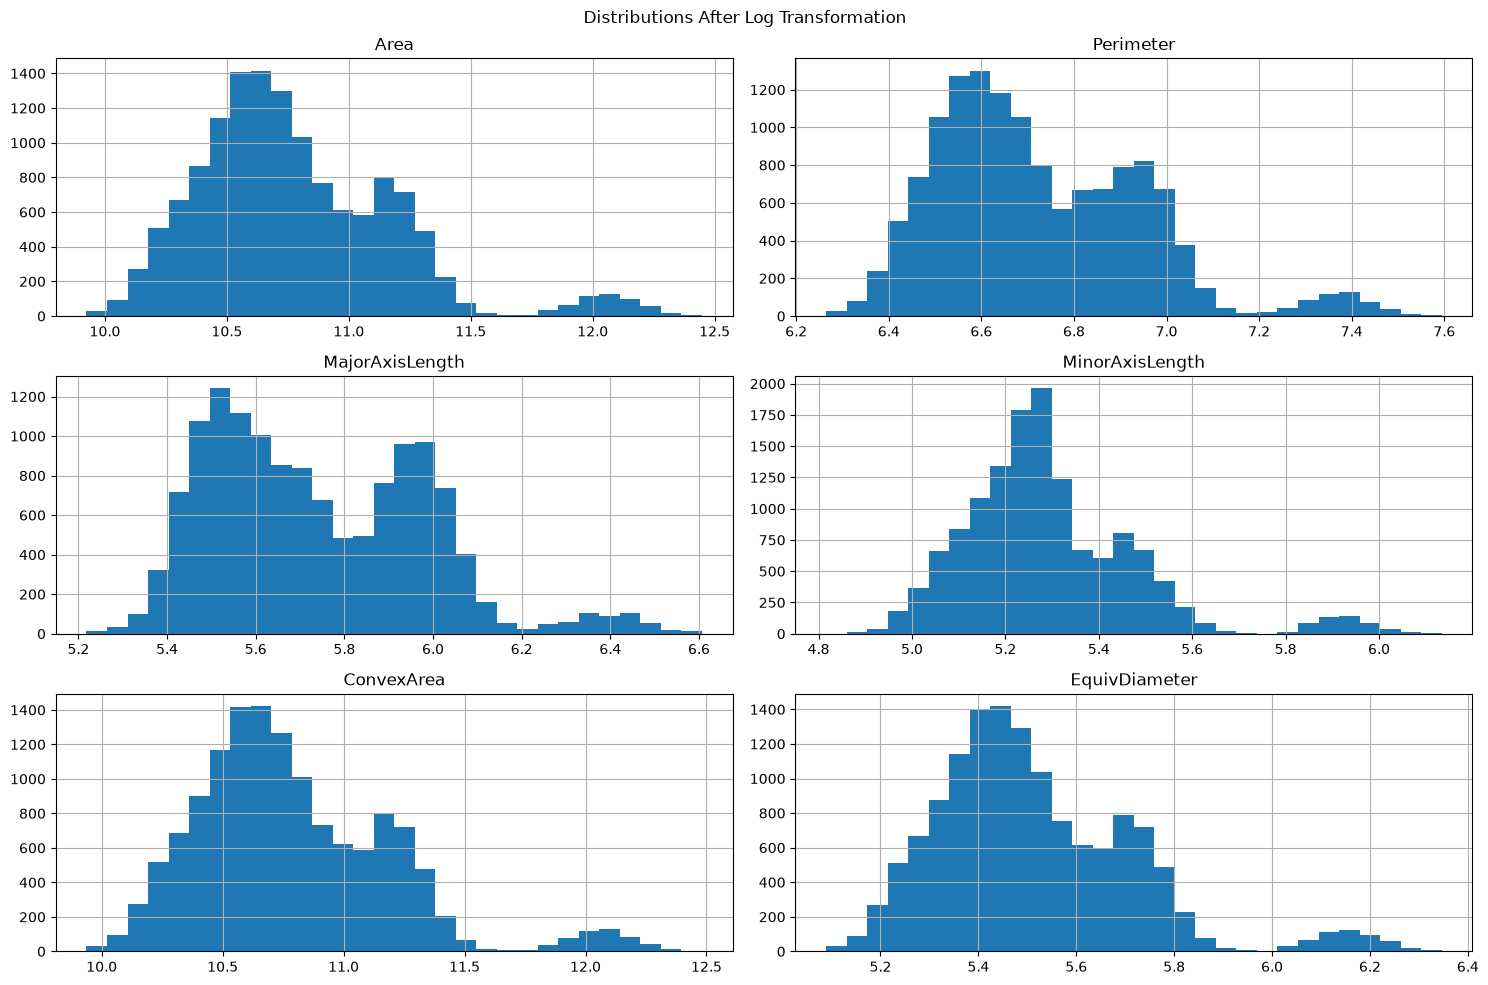

In [25]:
df[skewed_features].hist(figsize=(15, 10), bins=30)
plt.suptitle("Distributions After Log Transformation")
plt.tight_layout()
plt.show()

In [26]:
#train test split
X = df.drop("Class", axis=1)
y = df["Class"]

In [27]:
X.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,10.254004,6.415573,5.343186,5.164150,1.197191,0.549812,10.265210,5.253012,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,10.265871,6.459933,5.305912,5.213491,1.097356,0.411785,10.280999,5.258915,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,10.288103,6.437928,5.365163,5.175761,1.209713,0.562727,10.298599,5.269974,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,10.309253,6.472167,5.354499,5.212305,1.153638,0.498616,10.332832,5.280495,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,10.313642,6.431547,5.312456,5.253735,1.060798,0.333680,10.322790,5.282678,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


In [28]:
y.head()

0    SEKER
1    SEKER
2    SEKER
3    SEKER
4    SEKER
Name: Class, dtype: str

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [31]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (10834, 16)
X_test shape: (2709, 16)
y_train shape: (10834,)
y_test shape: (2709,)


In [32]:
print("Training class distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

Training class distribution:
Class
DERMASON    0.261861
SIRA        0.194665
SEKER       0.149622
HOROZ       0.137345
CALI        0.120362
BARBUNYA    0.097563
BOMBAY      0.038582
Name: proportion, dtype: float64

Testing class distribution:
Class
DERMASON    0.261720
SIRA        0.194537
SEKER       0.149871
HOROZ       0.137320
CALI        0.120340
BARBUNYA    0.097822
BOMBAY      0.038391
Name: proportion, dtype: float64


In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

In [35]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [36]:
y_train_pred_lr = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

In [37]:
lr_train_accuracy = accuracy_score(y_train, y_train_pred_lr)
lr_test_accuracy = accuracy_score(y_test, y_test_pred_lr)

print("Training Accuracy:", lr_train_accuracy)
print("Testing Accuracy:", lr_test_accuracy)

Training Accuracy: 0.9256968801919881
Testing Accuracy: 0.9191583610188261


In [38]:
print(classification_report(y_test, y_test_pred_lr))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.95      0.96       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [39]:
lr_f1 = f1_score(y_test, y_test_pred_lr, average="weighted")

print("Weighted F1 Score:", lr_f1)

Weighted F1 Score: 0.9192781308916149


Logistic Regression Observation: The Logistic Regression model achieved a training accuracy of 92.57% and testing accuracy of 91.92%, with a weighted F1-score of 91.93%. The small difference between training and testing accuracy indicates that the model generalizes well with no significant overfitting. Performance across the individual classes is also strong, although relatively lower performance is observed for the SIRA class.

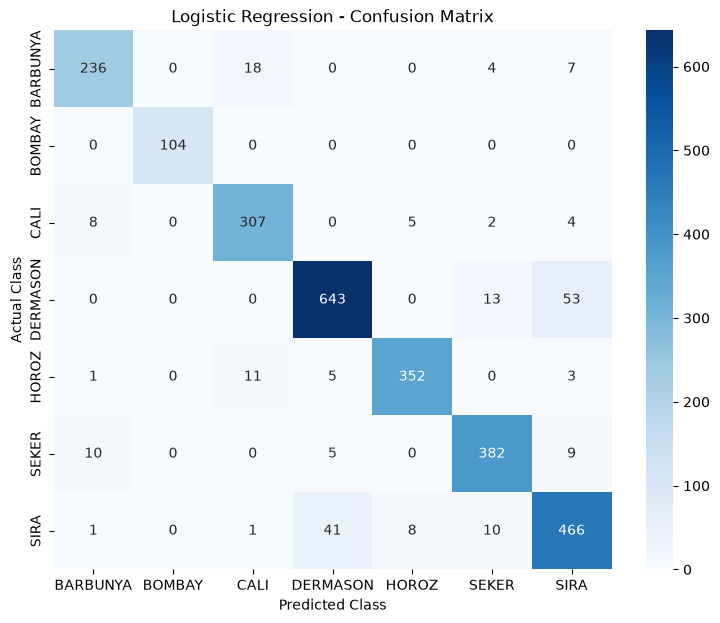

In [40]:
cm_lr = confusion_matrix(y_test, y_test_pred_lr)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Confusion Matrix Observation: Logistic Regression correctly classified most bean varieties. BOMBAY achieved perfect classification in the test set. The largest misclassification occurred between DERMASON and SIRA, indicating similarity in their physical characteristics. Some confusion was also observed between BARBUNYA and CALI.

In [41]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

cv_scores_lr = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores_lr)
print("Mean CV Accuracy:", cv_scores_lr.mean())
print("CV Standard Deviation:", cv_scores_lr.std())

CV Scores: [0.9247808  0.922012   0.92108906 0.92247347 0.92751616]
Mean CV Accuracy: 0.9235742977534672
CV Standard Deviation: 0.002316157401997115


Cross-Validation Observation: Logistic Regression achieved a mean 5-fold cross-validation accuracy of 92.36% with a low standard deviation of 0.23%. The consistency of the cross-validation scores indicates stable model performance and good generalization.

In [42]:
#model 2-decision tree classifier
from sklearn.tree import DecisionTreeClassifier

In [43]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [44]:
X_train

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
4285,11.148679,6.976010,5.991715,5.420561,1.773733,0.825923,11.171688,5.698471,0.707386,0.977254,0.763027,0.745203,0.005745,0.001093,0.555328,0.985004
3216,11.325125,7.059258,5.973344,5.605199,1.446694,0.722634,11.340618,5.786412,0.825986,0.984627,0.770544,0.829065,0.004728,0.001378,0.687349,0.994384
7320,11.082804,6.931966,6.040738,5.298131,2.106941,0.880190,11.093600,5.665645,0.783403,0.989262,0.780231,0.686480,0.006445,0.000883,0.471255,0.992906
8034,10.629005,6.633213,5.664481,5.217365,1.566869,0.769858,10.638376,5.439623,0.791930,0.990672,0.901417,0.797929,0.006957,0.001740,0.636691,0.997611
5401,11.419592,7.064456,6.131880,5.541069,1.808623,0.833243,11.427368,5.833505,0.789051,0.992255,0.838119,0.741461,0.005042,0.000940,0.549765,0.994318
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,10.429369,6.495309,5.411528,5.270348,1.152415,0.497014,10.438430,5.340258,0.782128,0.990980,0.973136,0.930902,0.006589,0.003052,0.866579,0.998659
9741,10.822016,6.744826,5.746736,5.343271,1.499390,0.745113,10.846595,5.535731,0.796323,0.975719,0.874349,0.809160,0.006230,0.001647,0.654741,0.981712
839,10.552866,6.588288,5.576736,5.227759,1.419869,0.709912,10.562224,5.401721,0.735279,0.990685,0.913970,0.838835,0.006875,0.002100,0.703643,0.999082
2680,11.149226,6.954499,5.926471,5.477074,1.569750,0.770827,11.164006,5.698744,0.731366,0.985328,0.797039,0.795796,0.005378,0.001331,0.633292,0.994110


In [45]:
y_train_pred_dt = dt_model.predict(X_train)
y_test_pred_dt = dt_model.predict(X_test)

In [46]:
dt_train_accuracy = accuracy_score(y_train, y_train_pred_dt)
dt_test_accuracy = accuracy_score(y_test, y_test_pred_dt)

print("Training Accuracy:", dt_train_accuracy)
print("Testing Accuracy:", dt_test_accuracy)

Training Accuracy: 1.0
Testing Accuracy: 0.8951642672572905


The baseline Decision Tree achieved 100% training accuracy and 89.52% testing accuracy. The significant difference between training and testing performance indicates that the model is overfitting the training data. Hyperparameter tuning will be performed later to control the complexity of the tree and improve generalization.

In [47]:
print(classification_report(y_test, y_test_pred_dt))

              precision    recall  f1-score   support

    BARBUNYA       0.88      0.89      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.89      0.91      0.90       326
    DERMASON       0.89      0.90      0.89       709
       HOROZ       0.95      0.92      0.94       372
       SEKER       0.90      0.94      0.92       406
        SIRA       0.84      0.81      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.89      2709



The Decision Tree achieved 100% training accuracy but only 89.52% testing accuracy, indicating overfitting. The model achieved a weighted F1-score of approximately 0.89. Performance was lowest for the SIRA class (F1-score = 0.82), while BOMBAY was classified perfectly. Hyperparameter tuning will be performed later to reduce overfitting and improve generalization.

In [48]:
dt_f1 = f1_score(y_test, y_test_pred_dt, average="weighted")

print("Weighted F1 Score:", dt_f1)

Weighted F1 Score: 0.8949188527245702


In [49]:
cv_scores_dt = cross_val_score(
    dt_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores_dt)
print("Mean CV Accuracy:", cv_scores_dt.mean())
print("CV Standard Deviation:", cv_scores_dt.std())

CV Scores: [0.90586064 0.89386248 0.88694047 0.89570835 0.90304709]
Mean CV Accuracy: 0.8970838068381554
CV Standard Deviation: 0.006749067777361934


Cross-Validation Observation: The Decision Tree achieved a mean 5-fold cross-validation accuracy of 89.71%. Although cross-validation and test performance are consistent, the 100% training accuracy compared with approximately 89.5% test accuracy indicates overfitting.

In [50]:
#tune decision tree classifier with GridSearchCV
from sklearn.model_selection import GridSearchCV

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_dt.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",Tr

In [51]:
print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV Accuracy:", grid_search_dt.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV Accuracy: 0.9109284273759716


In [52]:
dt_tuned = grid_search_dt.best_estimator_

In [53]:
y_train_pred_dt_tuned = dt_tuned.predict(X_train)
y_test_pred_dt_tuned = dt_tuned.predict(X_test)

In [54]:
dt_tuned_train_accuracy = accuracy_score(
    y_train, y_train_pred_dt_tuned
)

dt_tuned_test_accuracy = accuracy_score(
    y_test, y_test_pred_dt_tuned
)

print("Tuned Training Accuracy:", dt_tuned_train_accuracy)
print("Tuned Testing Accuracy:", dt_tuned_test_accuracy)

Tuned Training Accuracy: 0.9510799335425513
Tuned Testing Accuracy: 0.9051310446659284


Hyperparameter Tuning Observation: GridSearchCV was applied to reduce overfitting in the Decision Tree. After tuning, training accuracy decreased from 100% to 95.11%, while testing accuracy improved from 89.52% to 90.51%. The train-test gap reduced considerably, indicating improved generalization. The best cross-validation accuracy was approximately 91.09%.

In [55]:
dt_tuned_f1 = f1_score(
    y_test,
    y_test_pred_dt_tuned,
    average="weighted"
)

print("Tuned Weighted F1 Score:", dt_tuned_f1)

Tuned Weighted F1 Score: 0.9052061051436571


In [56]:
print(classification_report(y_test, y_test_pred_dt_tuned))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.93      0.92       326
    DERMASON       0.90      0.90      0.90       709
       HOROZ       0.96      0.92      0.94       372
       SEKER       0.92      0.94      0.93       406
        SIRA       0.84      0.84      0.84       527

    accuracy                           0.91      2709
   macro avg       0.92      0.92      0.92      2709
weighted avg       0.91      0.91      0.91      2709



Tuned Decision Tree Result: Hyperparameter tuning improved the Decision Tree's generalization. Test accuracy increased from 89.52% to 90.51%, and weighted F1-score increased from 89.49% to 90.52%. The training-test accuracy gap reduced from 10.48% to 4.60%, indicating a significant reduction in overfitting. Among the individual classes, BOMBAY achieved the highest F1-score, while SIRA remained comparatively more difficult to classify.

In [57]:
#model 3-random forest classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [58]:
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

In [59]:
rf_train_accuracy = accuracy_score(y_train, y_train_pred_rf)
rf_test_accuracy = accuracy_score(y_test, y_test_pred_rf)

print("Training Accuracy:", rf_train_accuracy)
print("Testing Accuracy:", rf_test_accuracy)

Training Accuracy: 1.0
Testing Accuracy: 0.9169435215946844


In [60]:
print(classification_report(y_test, y_test_pred_rf))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.93      0.92       326
    DERMASON       0.91      0.92      0.91       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.96      0.95       406
        SIRA       0.86      0.85      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [61]:
rf_f1 = f1_score(
    y_test,
    y_test_pred_rf,
    average="weighted"
)

print("Weighted F1 Score:", rf_f1)

Weighted F1 Score: 0.9168872723620085


In [62]:
cv_scores_rf = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores_rf)
print("Mean CV Accuracy:", cv_scores_rf.mean())
print("CV Standard Deviation:", cv_scores_rf.std())

CV Scores: [0.92616521 0.92108906 0.92616521 0.9247808  0.9265928 ]
Mean CV Accuracy: 0.9249586149328828
CV Standard Deviation: 0.0020291536179041897


In [63]:
from sklearn.model_selection import RandomizedSearchCV

param_dist_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

random_search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist_rf,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

random_search_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 15, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Als

In [64]:
print("Best Parameters:", random_search_rf.best_params_)
print("Best CV Accuracy:", random_search_rf.best_score_)

Best Parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}
Best CV Accuracy: 0.9267124895765024


In [65]:
rf_tuned = random_search_rf.best_estimator_

y_train_pred_rf_tuned = rf_tuned.predict(X_train)
y_test_pred_rf_tuned = rf_tuned.predict(X_test)

In [66]:
rf_tuned_train_accuracy = accuracy_score(
    y_train, y_train_pred_rf_tuned
)

rf_tuned_test_accuracy = accuracy_score(
    y_test, y_test_pred_rf_tuned
)

print("Tuned Training Accuracy:", rf_tuned_train_accuracy)
print("Tuned Testing Accuracy:", rf_tuned_test_accuracy)

Tuned Training Accuracy: 0.9944618792689681
Tuned Testing Accuracy: 0.9187892211148025


In [67]:
rf_tuned_f1 = f1_score(
    y_test,
    y_test_pred_rf_tuned,
    average="weighted"
)

print("Tuned Weighted F1 Score:", rf_tuned_f1)

Tuned Weighted F1 Score: 0.9186479125504897


Random Forest Hyperparameter Tuning: RandomizedSearchCV was used to optimize the Random Forest model. After tuning, test accuracy improved from 91.69% to 91.88%, while training accuracy decreased from 100% to 99.45%. The weighted F1-score was 91.86%, and the best cross-validation accuracy was 92.67%. Hyperparameter tuning slightly improved generalization, although some overfitting remained.

In [68]:
#Model 4 KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](7,)","['BARBUNYA','BOMBAY','CALI',...,'HOROZ','SEKER','SIRA']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [69]:
y_train_pred_knn = knn_model.predict(X_train_scaled)
y_test_pred_knn = knn_model.predict(X_test_scaled)

In [70]:
knn_train_accuracy = accuracy_score(y_train, y_train_pred_knn)
knn_test_accuracy = accuracy_score(y_test, y_test_pred_knn)

print("Training Accuracy:", knn_train_accuracy)
print("Testing Accuracy:", knn_test_accuracy)

Training Accuracy: 0.944341886653129
Testing Accuracy: 0.9147286821705426


In [71]:
print(classification_report(y_test, y_test_pred_knn))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.88      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.94      0.92       326
    DERMASON       0.91      0.92      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.95      0.93      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.91      2709
   macro avg       0.93      0.92      0.93      2709
weighted avg       0.92      0.91      0.91      2709



In [72]:
knn_f1 = f1_score(
    y_test,
    y_test_pred_knn,
    average="weighted"
)

print("Weighted F1 Score:", knn_f1)

Weighted F1 Score: 0.9149075433935798


In [73]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

cv_scores_knn = cross_val_score(
    knn_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores_knn)
print("Mean CV Accuracy:", cv_scores_knn.mean())
print("CV Standard Deviation:", cv_scores_knn.std())

CV Scores: [0.91739732 0.9233964  0.922012   0.92385787 0.9242844 ]
Mean CV Accuracy: 0.9221895970830826
CV Standard Deviation: 0.002514959612570753


KNN Observation: The KNN classifier achieved 94.43% training accuracy and 91.47% testing accuracy, with a weighted F1-score of 91.49%. The mean 5-fold cross-validation accuracy was 92.22% with a low standard deviation, indicating stable performance. The relatively small train-test gap suggests no significant overfitting.

In [74]:
#TUNING kNN
from sklearn.model_selection import GridSearchCV

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

grid_search_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_knn.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__metric': ['euclidean', 'manhattan'], 'knn__n_neighbors': [3, 5, ...], 'knn__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbos

In [75]:
print("Best Parameters:", grid_search_knn.best_params_)
print("Best CV Accuracy:", grid_search_knn.best_score_)

Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 15, 'knn__weights': 'distance'}
Best CV Accuracy: 0.9259738859693863


In [76]:
knn_tuned = grid_search_knn.best_estimator_

y_train_pred_knn_tuned = knn_tuned.predict(X_train)
y_test_pred_knn_tuned = knn_tuned.predict(X_test)

In [77]:
knn_tuned_train_accuracy = accuracy_score(
    y_train,
    y_train_pred_knn_tuned
)

knn_tuned_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_knn_tuned
)

print("Tuned Training Accuracy:", knn_tuned_train_accuracy)
print("Tuned Testing Accuracy:", knn_tuned_test_accuracy)

Tuned Training Accuracy: 1.0
Tuned Testing Accuracy: 0.9150978220745662


In [78]:
knn_tuned_f1 = f1_score(
    y_test,
    y_test_pred_knn_tuned,
    average="weighted"
)

print("Tuned Weighted F1 Score:", knn_tuned_f1)

Tuned Weighted F1 Score: 0.9152490797313924


KNN Hyperparameter Tuning Observation: Hyperparameter tuning produced a test accuracy of 91.51% and weighted F1-score of 91.52%, which were only marginally higher than the baseline model. However, tuned training accuracy increased to 100%, indicating increased overfitting. Therefore, the baseline KNN model was retained because it provided a better balance between training and testing performance.

In [79]:
#model 5 SVM
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [80]:
y_train_pred_svm = svm_model.predict(X_train_scaled)
y_test_pred_svm = svm_model.predict(X_test_scaled)

In [81]:
svm_train_accuracy = accuracy_score(
    y_train,
    y_train_pred_svm
)

svm_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_svm
)

print("Training Accuracy:", svm_train_accuracy)
print("Testing Accuracy:", svm_test_accuracy)

Training Accuracy: 0.9348347793981909
Testing Accuracy: 0.9213732004429679


In [82]:
print(classification_report(y_test, y_test_pred_svm))

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.96      0.95      0.96       372
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [83]:
svm_f1 = f1_score(
    y_test,
    y_test_pred_svm,
    average="weighted"
)

print("Weighted F1 Score:", svm_f1)

Weighted F1 Score: 0.9213986190227275


In [84]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", random_state=42))
])

cv_scores_svm = cross_val_score(
    svm_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores_svm)
print("Mean CV Accuracy:", cv_scores_svm.mean())
print("CV Standard Deviation:", cv_scores_svm.std())

CV Scores: [0.93677896 0.92985695 0.92801108 0.92754961 0.93536473]
Mean CV Accuracy: 0.9315122625498485
CV Standard Deviation: 0.003828330707068175


SVM Observation: The SVM classifier achieved 93.48% training accuracy and 92.14% testing accuracy, with a weighted F1-score of 92.14%. The mean 5-fold cross-validation accuracy was 93.15%. The small difference between training and testing accuracy indicates good generalization with no significant overfitting.Therefore, additional hyperparameter tuning was not considered necessary at this stage.

In [85]:
#model 6 NaiveBayes
from sklearn.naive_bayes import GaussianNB


In [86]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](7,)","[1057., 418.,1304.,...,1488.,1621.,2109.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](7,)","[0.1 ,0.04,0.12,...,0.14,0.15,0.19]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U8](7,)","['BARBUNYA','BOMBAY','CALI',...,'HOROZ','SEKER','SIRA']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.704e-10
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['Area','Perimeter','MajorAxisLength',...,'ShapeFactor2','ShapeFactor3', 'ShapeFactor4']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](7, 16)","[[11.14, 6.95, 5.91,..., 0. , 0.65, 1. ], [12.05, 7.37, 6.38,..., 0. , 0.63, 0.99], [11.22, 6.96, 6.01,..., 0. , 0.57, 0.99], ..., [10.88, 6.82, 5.92,..., 0. , 0.49, 0.99], [10.59, 6.59, 5.53,..., 0. , 0.81, 1. ], [10.7 , 6.68, 5.7 ,..., 0. , 0.64, 1. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](7, 16)","[[0.02,0.01,0.01,...,0. ,0. ,0. ], [0.02,0.01,0.01,...,0. ,0. ,0. ], [0.02,0. ,0.01,...,0. ,0. ,0. ], ..., [0.02,0.01,0.01,...,0. ,0. ,0. ], [0.01,0. ,0.01,...,0. ,0. ,0. ], [0.01,0. ,0. ,...,0. ,0. ,0. ]]"


In [87]:
y_train_pred_nb = nb_model.predict(X_train)
y_test_pred_nb = nb_model.predict(X_test)

In [88]:
nb_train_accuracy = accuracy_score(
    y_train,
    y_train_pred_nb
)

nb_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_nb
)

print("Training Accuracy:", nb_train_accuracy)
print("Testing Accuracy:", nb_test_accuracy)

Training Accuracy: 0.8954218201956803
Testing Accuracy: 0.896640826873385


In [89]:
print(classification_report(y_test, y_test_pred_nb))

              precision    recall  f1-score   support

    BARBUNYA       0.87      0.79      0.83       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.86      0.92      0.89       326
    DERMASON       0.94      0.86      0.90       709
       HOROZ       0.95      0.95      0.95       372
       SEKER       0.92      0.94      0.93       406
        SIRA       0.81      0.90      0.85       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709



In [90]:
nb_f1 = f1_score(
    y_test,
    y_test_pred_nb,
    average="weighted"
)

print("Weighted F1 Score:", nb_f1)

Weighted F1 Score: 0.896831387542501


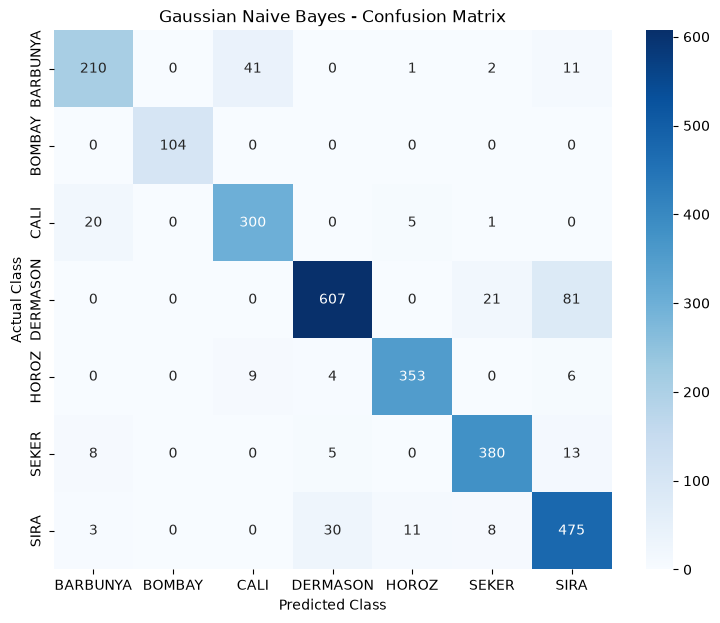

In [91]:
cm_nb = confusion_matrix(y_test, y_test_pred_nb)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nb_model.classes_,
    yticklabels=nb_model.classes_
)

plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [92]:
cv_scores_nb = cross_val_score(
    nb_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores_nb)
print("Mean CV Accuracy:", cv_scores_nb.mean())
print("CV Standard Deviation:", cv_scores_nb.std())

CV Scores: [0.90078449 0.89524689 0.89017074 0.89155515 0.89935365]
Mean CV Accuracy: 0.8954221830777366
CV Standard Deviation: 0.004165888379732009


Gaussian Naive Bayes Observation: Gaussian Naive Bayes achieved 89.54% training accuracy, 89.66% testing accuracy, and a weighted F1-score of 89.68%. The mean 5-fold cross-validation accuracy was 89.54%. The close training, testing, and cross-validation performance indicates stable generalization with no evidence of overfitting. However, its overall predictive performance was lower than several other classifiers evaluated in this project.

In [93]:
#model 7-ensemble learning 
from sklearn.ensemble import VotingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

Logistic Regression + Decision Tree + SVM → Voting Classifier

In [94]:
lr_vote = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000))
])

In [95]:
dt_vote = dt_tuned

In [96]:
svm_vote = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

In [97]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", lr_vote),
        ("dt", dt_vote),
        ("svm", svm_vote)
    ],
    voting="hard"
)

In [98]:
voting_model.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('dt', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](7,)","['BARBUNYA','BOMBAY','CALI',...,'HOROZ','SEKER','SIRA']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[Pipeline(step..._iter=1000))]), DecisionTreeC...ndom_state=42), Pipeline(step...svm', SVC())])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Area','Perimeter','MajorAxisLength',...,'ShapeFactor2','ShapeFactor3', 'ShapeFactor4']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [99]:
y_train_pred_vote = voting_model.predict(X_train)
y_test_pred_vote = voting_model.predict(X_test)

In [100]:
vote_train_accuracy = accuracy_score(
    y_train,
    y_train_pred_vote
)

vote_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_vote
)

print("Training Accuracy:", vote_train_accuracy)
print("Testing Accuracy:", vote_test_accuracy)

Training Accuracy: 0.9374192357393392
Testing Accuracy: 0.920265780730897


In [101]:
print(classification_report(y_test, y_test_pred_vote))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.92       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.97      0.93      0.95       372
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [102]:
vote_f1 = f1_score(
    y_test,
    y_test_pred_vote,
    average="weighted"
)

print("Weighted F1 Score:", vote_f1)

Weighted F1 Score: 0.9203837045487785


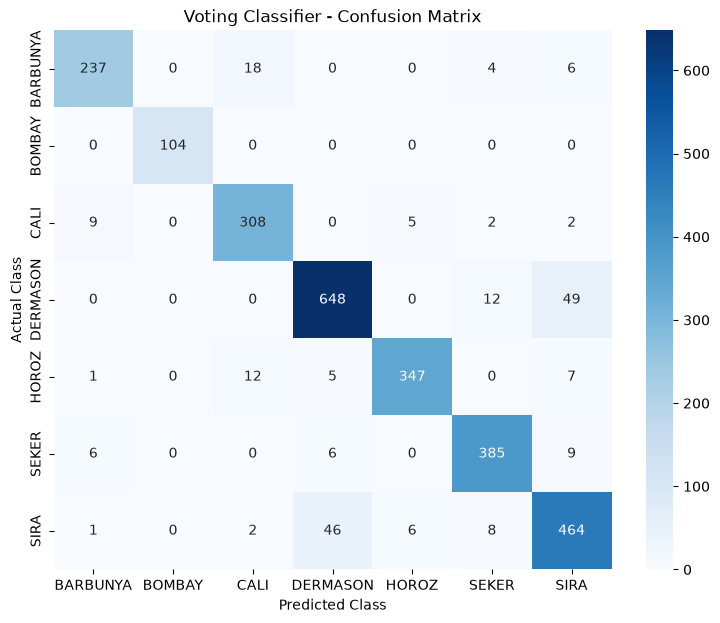

In [103]:
cm_vote = confusion_matrix(y_test, y_test_pred_vote)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_vote,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=voting_model.classes_,
    yticklabels=voting_model.classes_
)

plt.title("Voting Classifier - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [104]:
cv_scores_vote = cross_val_score(
    voting_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores_vote)
print("Mean CV Accuracy:", cv_scores_vote.mean())
print("CV Standard Deviation:", cv_scores_vote.std())

CV Scores: [0.93170281 0.92754961 0.92708814 0.92801108 0.93444137]
Mean CV Accuracy: 0.9297586009567673
CV Standard Deviation: 0.0028556302022266517


Voting Classifier Result: The Hard Voting Classifier achieved 93.74% training accuracy, 92.03% testing accuracy, and a weighted F1-score of 92.04%. The mean 5-fold cross-validation accuracy was 92.98% with a low standard deviation of approximately 0.28%, indicating stable performance and good generalization across different subsets of the data.

In [105]:
#check class imbalance
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [106]:
from imblearn.over_sampling import SMOTE

print("SMOTE imported successfully!")

SMOTE imported successfully!


In [107]:
print("Class Distribution Before SMOTE:")
print(y_train.value_counts())

Class Distribution Before SMOTE:
Class
DERMASON    2837
SIRA        2109
SEKER       1621
HOROZ       1488
CALI        1304
BARBUNYA    1057
BOMBAY       418
Name: count, dtype: int64


In [108]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [109]:
print("Class Distribution After SMOTE:")
print(y_train_smote.value_counts())

Class Distribution After SMOTE:
Class
CALI        2837
BARBUNYA    2837
HOROZ       2837
SIRA        2837
DERMASON    2837
SEKER       2837
BOMBAY      2837
Name: count, dtype: int64


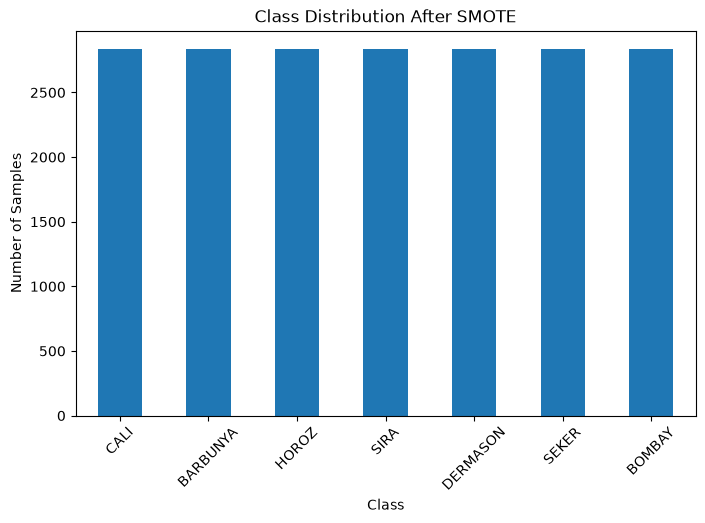

In [110]:
plt.figure(figsize=(8, 5))

y_train_smote.value_counts().plot(kind="bar")

plt.title("Class Distribution After SMOTE")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.show()

In [111]:
scaler_smote = StandardScaler()

X_train_smote_scaled = scaler_smote.fit_transform(X_train_smote)
X_test_smote_scaled = scaler_smote.transform(X_test)

In [112]:
svm_smote = SVC(
    kernel="rbf",
    random_state=42
)

svm_smote.fit(X_train_smote_scaled, y_train_smote)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [113]:
y_test_pred_svm_smote = svm_smote.predict(X_test_smote_scaled)

In [114]:
svm_smote_accuracy = accuracy_score(
    y_test,
    y_test_pred_svm_smote
)

print("Test Accuracy After SMOTE:", svm_smote_accuracy)

Test Accuracy After SMOTE: 0.9224806201550387


In [115]:
print(classification_report(
    y_test,
    y_test_pred_svm_smote
))

              precision    recall  f1-score   support

    BARBUNYA       0.91      0.92      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.94      0.90      0.92       709
       HOROZ       0.96      0.95      0.96       372
       SEKER       0.93      0.96      0.94       406
        SIRA       0.86      0.89      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.94      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [116]:
svm_smote_f1 = f1_score(
    y_test,
    y_test_pred_svm_smote,
    average="weighted"
)

print("Weighted F1 Score After SMOTE:", svm_smote_f1)

Weighted F1 Score After SMOTE: 0.92264620244402


In [117]:
svm_smote_macro_f1 = f1_score(
    y_test,
    y_test_pred_svm_smote,
    average="macro"
)

print("Macro F1 Score After SMOTE:", svm_smote_macro_f1)

Macro F1 Score After SMOTE: 0.9338942262815567


Class Imbalance Treatment: The training dataset showed class imbalance, with DERMASON having 2,837 samples and BOMBAY having 418 samples. SMOTE was applied only to the training data to balance all classes to 2,837 samples. After applying SMOTE, SVM achieved a weighted F1-score of 0.9223 and macro F1-score of 0.9339. Compared with the original SVM weighted F1-score of 0.9214, the improvement was marginal. Therefore, although SMOTE successfully balanced the classes, it did not significantly improve model performance.

In [119]:
from sklearn.metrics import classification_report
import pandas as pd

# Before SMOTE
report_before = classification_report(
    y_test,
    y_test_pred_svm,
    output_dict=True
)

# After SMOTE
report_after = classification_report(
    y_test,
    y_test_pred_svm_smote,
    output_dict=True
)

classes = y_test.unique()

comparison_smote = pd.DataFrame({
    "F1 Before SMOTE": [
        report_before[c]["f1-score"] for c in classes
    ],
    "F1 After SMOTE": [
        report_after[c]["f1-score"] for c in classes
    ]
}, index=classes)

comparison_smote["Difference"] = (
    comparison_smote["F1 After SMOTE"]
    - comparison_smote["F1 Before SMOTE"]
)

comparison_smote.round(3)

,F1 Before SMOTE,F1 After SMOTE,Difference
SEKER,0.944,0.941,-0.003
DERMASON,0.916,0.917,0.001
HOROZ,0.955,0.957,0.001
BARBUNYA,0.911,0.914,0.003
SIRA,0.870,0.874,0.004
BOMBAY,1.000,1.000,0.000
CALI,0.934,0.936,0.002


In [120]:
#compare all the models
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree (Tuned)",
        "Random Forest (Tuned)",
        "KNN",
        "SVM",
        "Naive Bayes",
        "Voting Classifier"
    ],

    "Training Accuracy": [
        lr_train_accuracy,
        dt_tuned_train_accuracy,
        rf_tuned_train_accuracy,
        knn_train_accuracy,
        svm_train_accuracy,
        nb_train_accuracy,
        vote_train_accuracy
    ],

    "Testing Accuracy": [
        lr_test_accuracy,
        dt_tuned_test_accuracy,
        rf_tuned_test_accuracy,
        knn_test_accuracy,
        svm_test_accuracy,
        nb_test_accuracy,
        vote_test_accuracy
    ],

    "Weighted F1 Score": [
        lr_f1,
        dt_tuned_f1,
        rf_tuned_f1,
        knn_f1,
        svm_f1,
        nb_f1,
        vote_f1
    ]
})

model_comparison.round(4)

,Model,Training Accuracy,Testing Accuracy,Weighted F1 Score
0,Logistic Regression,0.9257,0.9192,0.9193
1,Decision Tree (Tuned),0.9511,0.9051,0.9052
2,Random Forest (Tuned),0.9945,0.9188,0.9186
3,KNN,0.9443,0.9147,0.9149
4,SVM,0.9348,0.9214,0.9214
5,Naive Bayes,0.8954,0.8966,0.8968
6,Voting Classifier,0.9374,0.9203,0.9204


In [121]:
model_comparison["Train-Test Gap"] = (
    model_comparison["Training Accuracy"]
    - model_comparison["Testing Accuracy"]
)

model_comparison.round(4)

,Model,Training Accuracy,Testing Accuracy,Weighted F1 Score,Train-Test Gap
0,Logistic Regression,0.9257,0.9192,0.9193,0.0065
1,Decision Tree (Tuned),0.9511,0.9051,0.9052,0.0459
2,Random Forest (Tuned),0.9945,0.9188,0.9186,0.0757
3,KNN,0.9443,0.9147,0.9149,0.0296
4,SVM,0.9348,0.9214,0.9214,0.0135
5,Naive Bayes,0.8954,0.8966,0.8968,-0.0012
6,Voting Classifier,0.9374,0.9203,0.9204,0.0172


In [122]:
model_comparison["Mean CV Accuracy"] = [
    cv_scores_lr.mean(),
    grid_search_dt.best_score_,
    random_search_rf.best_score_,
    cv_scores_knn.mean(),
    cv_scores_svm.mean(),
    cv_scores_nb.mean(),
    cv_scores_vote.mean()
]

model_comparison.round(4)

,Model,Training Accuracy,Testing Accuracy,Weighted F1 Score,Train-Test Gap,Mean CV Accuracy
0,Logistic Regression,0.9257,0.9192,0.9193,0.0065,0.9236
1,Decision Tree (Tuned),0.9511,0.9051,0.9052,0.0459,0.9109
2,Random Forest (Tuned),0.9945,0.9188,0.9186,0.0757,0.9267
3,KNN,0.9443,0.9147,0.9149,0.0296,0.9222
4,SVM,0.9348,0.9214,0.9214,0.0135,0.9315
5,Naive Bayes,0.8954,0.8966,0.8968,-0.0012,0.8954
6,Voting Classifier,0.9374,0.9203,0.9204,0.0172,0.9298


In [123]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN",
        "Naive Bayes",
        "Voting Classifier"
    ],
    
    "Train Accuracy": [
        lr_train_accuracy,
        dt_tuned_train_accuracy,
        rf_tuned_train_accuracy,
        svm_train_accuracy,
        knn_train_accuracy,
        nb_train_accuracy,
        vote_train_accuracy
    ],
    
    "Test Accuracy": [
        lr_test_accuracy,
        dt_tuned_test_accuracy,
        rf_tuned_test_accuracy,
        svm_test_accuracy,
        knn_test_accuracy,
        nb_test_accuracy,
        vote_test_accuracy
    ],
    
    "F1 Score": [
        lr_f1,
        dt_tuned_f1,
        rf_tuned_f1,
        svm_f1,
        knn_f1,
        nb_f1,
        vote_f1
    ]
})

model_comparison.round(4)

,Model,Train Accuracy,Test Accuracy,F1 Score
0,Logistic Regression,0.9257,0.9192,0.9193
1,Decision Tree,0.9511,0.9051,0.9052
2,Random Forest,0.9945,0.9188,0.9186
3,SVM,0.9348,0.9214,0.9214
4,KNN,0.9443,0.9147,0.9149
5,Naive Bayes,0.8954,0.8966,0.8968
6,Voting Classifier,0.9374,0.9203,0.9204


In [124]:
model_comparison["Overfitting (Y/N)"] = (
    model_comparison["Train Accuracy"] -
    model_comparison["Test Accuracy"]
).apply(lambda x: "Y" if x > 0.05 else "N")

model_comparison.round(4)

,Model,Train Accuracy,Test Accuracy,F1 Score,Overfitting (Y/N)
0,Logistic Regression,0.9257,0.9192,0.9193,N
1,Decision Tree,0.9511,0.9051,0.9052,N
2,Random Forest,0.9945,0.9188,0.9186,Y
3,SVM,0.9348,0.9214,0.9214,N
4,KNN,0.9443,0.9147,0.9149,N
5,Naive Bayes,0.8954,0.8966,0.8968,N
6,Voting Classifier,0.9374,0.9203,0.9204,N


In [125]:
smote_row = pd.DataFrame({
    "Model": ["SVM + SMOTE"],
    "Train Accuracy": [None],
    "Test Accuracy": [
        accuracy_score(y_test, y_test_pred_svm_smote)
    ],
    "F1 Score": [svm_smote_f1],
    "Overfitting (Y/N)": ["N"]
})

model_comparison = pd.concat(
    [model_comparison, smote_row],
    ignore_index=True
)

model_comparison.round(4)

,Model,Train Accuracy,Test Accuracy,F1 Score,Overfitting (Y/N)
0,Logistic Regression,0.925697,0.9192,0.9193,N
1,Decision Tree,0.95108,0.9051,0.9052,N
2,Random Forest,0.994462,0.9188,0.9186,Y
3,SVM,0.934835,0.9214,0.9214,N
4,KNN,0.944342,0.9147,0.9149,N
5,Naive Bayes,0.895422,0.8966,0.8968,N
6,Voting Classifier,0.937419,0.9203,0.9204,N
7,SVM + SMOTE,None,0.9225,0.9226,N


In [126]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

svm_smote_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("svm", SVC(kernel="rbf", random_state=42))
])

cv_scores_svm_smote = cross_val_score(
    svm_smote_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores_svm_smote)
print("Mean CV Accuracy:", cv_scores_svm_smote.mean())
print("CV Standard Deviation:", cv_scores_svm_smote.std())

CV Scores: [0.93539455 0.92247347 0.92616521 0.93124135 0.93074792]
Mean CV Accuracy: 0.9292044991160534
CV Standard Deviation: 0.004458515745283258


In [127]:
model_comparison["Mean CV Accuracy"] = [
    0.9236,   # Logistic Regression
    0.9109,   # Decision Tree Tuned
    0.9267,   # Random Forest Tuned
    0.9315,   # SVM
    0.9222,   # KNN
    0.8954,   # Naive Bayes
    0.9298,   # Voting Classifier
    0.9292    # SVM + SMOTE
]

model_comparison.round(4)

,Model,Train Accuracy,Test Accuracy,F1 Score,Overfitting (Y/N),Mean CV Accuracy
0,Logistic Regression,0.925697,0.9192,0.9193,N,0.9236
1,Decision Tree,0.95108,0.9051,0.9052,N,0.9109
2,Random Forest,0.994462,0.9188,0.9186,Y,0.9267
3,SVM,0.934835,0.9214,0.9214,N,0.9315
4,KNN,0.944342,0.9147,0.9149,N,0.9222
5,Naive Bayes,0.895422,0.8966,0.8968,N,0.8954
6,Voting Classifier,0.937419,0.9203,0.9204,N,0.9298
7,SVM + SMOTE,None,0.9225,0.9226,N,0.9292


Final Model: SVM with SMOTE was selected as the final model. It achieved a test accuracy of 92.25%, weighted F1-score of 92.26%, and mean 5-fold cross-validation accuracy of 92.92%. SMOTE also helped improve the performance of several minority classes while maintaining good overall generalization.

In [129]:
import joblib


import joblib

joblib.dump(svm_smote, "svm_model.pkl")
joblib.dump(scaler_smote, "scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
